# CSC 349A Numerical Analysis - Lecture 20 - Open Newton-Cotes
We wrap up our lectures on quadrature by considering two more situations,
1. When we do not have the end points - Open Newton-Cotes
2. When the data points are not evenly spaced

## Open Newton-Cotes formula

The goal is to integrate an interpolating polynomial with all quadrature points $x_i$ in the open interval $(a,b)$. 

$$
h = \frac{b-a}{n+2}, \;\;\; n \geq 0  
$$

Construct an interpolating polynomial $P_n(x) = \sum_{i=0}^{n} L_i(x)f(x_i)$ of degree $n$ through $x_0, x_1, \dots, x_n$. Then 

$$
\int_{a}^{b} f(x)dx \approx \int_{a}^{b} P_n(x)dx = \sum_{i=0}^{n} \left ( \int_{a}^{b} L_i(x)dx \right ) f(x_i)
$$

**Note:** $f(x)$ is not evaluated at $a = x_1$ or $b = x_{n+1}$

### Case $n=0$: midpoint rule 

$$
\int_{a}^{b} f(x)dx \approx 2h f(x_0),\;\;\;\;  h = \frac{b-a}{2} 
$$

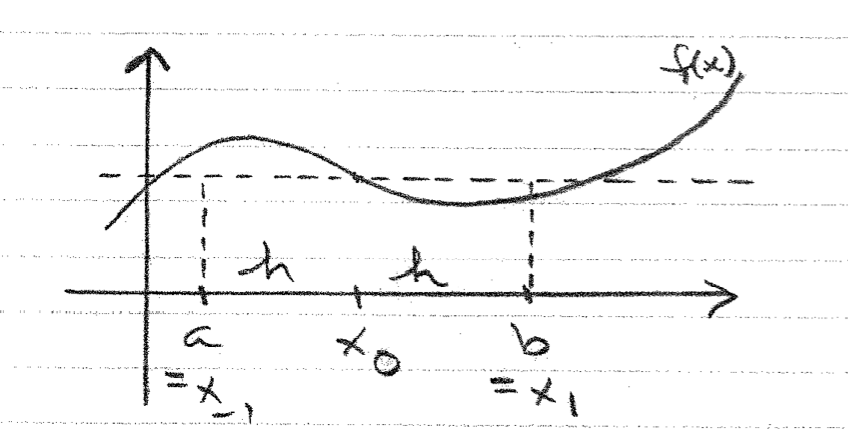

### Case $n=1$

$$
\int_{a}^{b} f(x) dx \approx \int_{x_1}^{x_2} \left [ \frac{x-x_1}{x_0 - x_1} 
 f(x_0) + \frac{x-x_0}{x_1-x_0} f(x_1) \right ] dx 
$$

To integrate this more easily, use a exchange of variable $t = \frac{x-x_0}{h}$ 
then:

\begin{align*} 
& x-x_0 = t h \\ 
& x-x_1 = x - (x_0 + h) = (x - x_0) -h = (t-1)h \\ 
& dx = h dt 
\end{align*} 

\begin{align*}
\int_{a}^{b} f(x) dx \approx & \int_{-1}^{2} \left [ \frac{(t-1)h}{-h}f(x_0) + \frac{th}{h}f(x_1) \right ] h dt \\
=& -h f(x_0) \int_{-1}^{2} (t-1)dt + h f(x_1) \int_{-1}^{2}t dt \\
=& \frac{3h}{2} \left [ f(x_0) + f(x_1) \right ] 
\end{align*} 

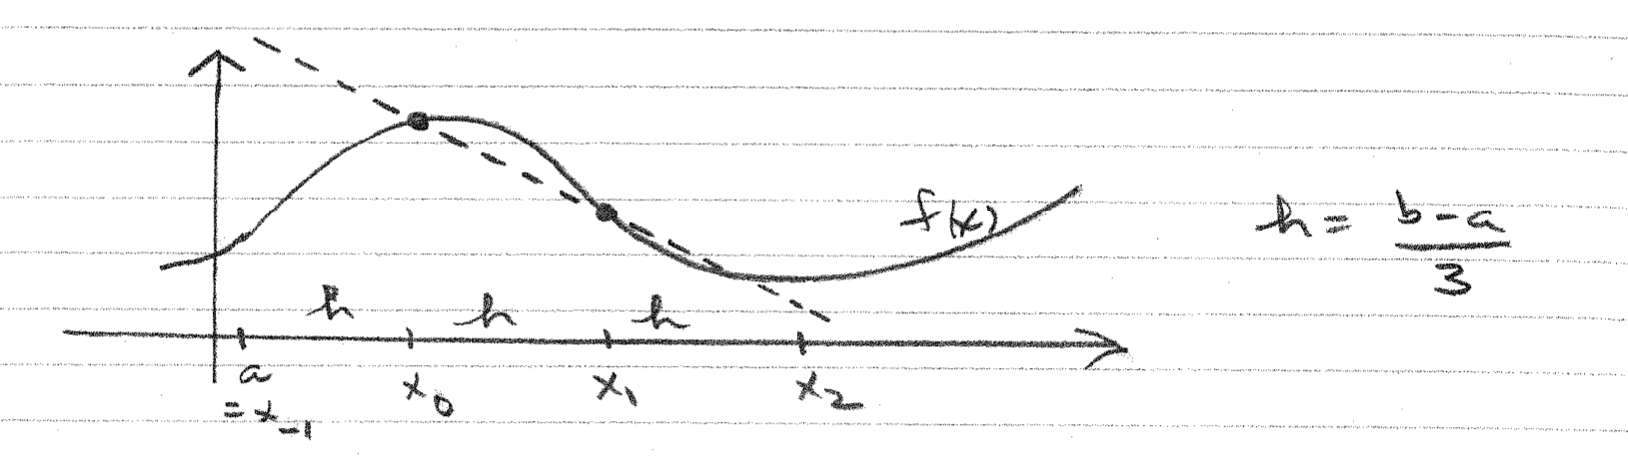

### Example - Use of open quadrature formulas: If $f(x)$ has a singularity. 

Consider $f(x)=\frac{1}{x}$ from $x=0$ to $x=0.09$, given $x_0=0.03$ and $x_1=0.06$. 

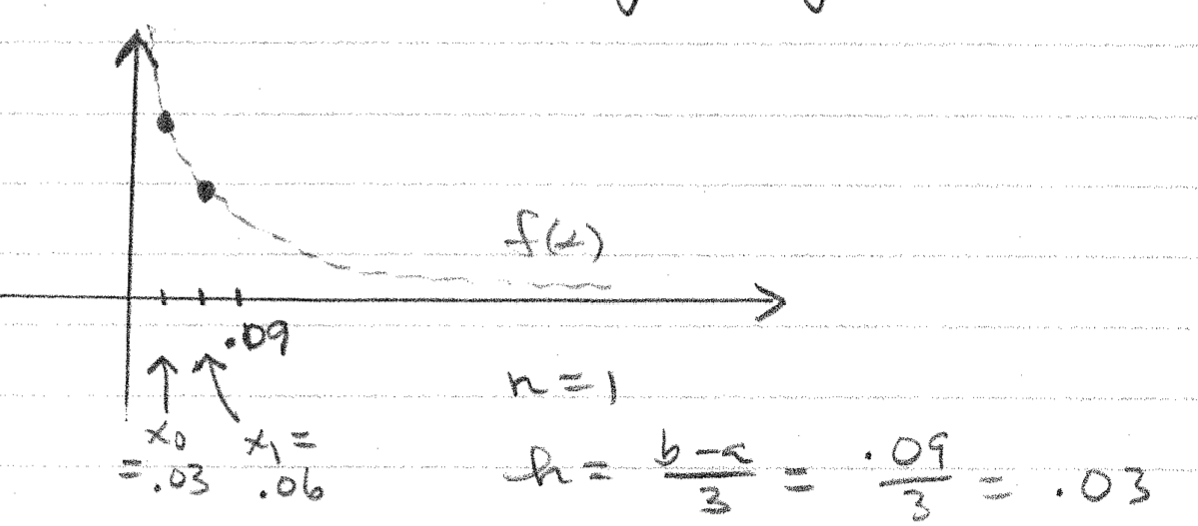

$$
h = \frac{b-a}{3} = \frac{.09}{3} = .03 
$$

and

$$
\int_0^{0.09} f(x)dx \approx \frac{3h}{2} \left [ f(x_0) + f(x_1) \right ] = \frac{3(.03)}{2} \left [ f(.03) + f(.06) \right ]= 2.25 
$$

The truncation error term is $\frac{3}{4} h^3 f''(\xi)$, for some $\xi \in (0,0.06)$

## Newton-Cotes Formulas with Unequal Segments
By way of example, consider the following 11 unequally spaced data points to numerically integrate $f(x)=0.2+25x-200x^2+675x^3-900x^4+400x^5$ from $a=0$ to $b=0.8$.:

| $x$ | $f(x)$ | $x$ | $f(x)$ |
|:------|:------|:------|:------|
|0.0 | 0.2 | 0.44 | 2.842985 |
|0.12 | 1.309729 | 0.54 | 3.507297 | 
|0.22 | 1.305241 | 0.64 | 3.181929 | 
|0.32 | 1.743393 | 0.70 |2.363 |
|0.36 | 2.074903 | 0.80 | 0.232 |
|0.40 | 2.456 | | |

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

def f(x):
    return 0.2 + 25*x - 200*x**2 + 675*x**3 - 900*x**4 + 400*x**5

x = np.arange(0, 0.81, 0.01)
fx = f(x)
x_points = np.array([0.0, 0.12, 0.22, 0.32, 0.36, 0.4, 0.44, 0.54, 0.64, 0.7, 0.8])
y_points = f(x_points)
plt.scatter(
    x_points,
    y_points,
    color="red",
    label="Highlighted Points",
)
plt.plot(x,fx,label='f(x)')
plt.legend()
plt.show()

We could interpolate with a polynomial of degree 10 but we know that should be avoided. Instead, we look for patterns in the lengths of the subintervals and apply the appropriate method over those subintervals. Note the following patterns in the data points:
* From 0 to 0.12 there are two points with $h_1=0.12$ - one application of the Trap. rule.
* From 0.12 to 0.32 there are three evenly spaced points with $h_2=0.10$ - one application of the Simpson's 1/3 rule.
* From 0.32 to 0.44 there are four evenly spaced points with $h_3=0.04$ - one application of the Simpson's 3/8 rule.
* From 0.44 to 0.64 there are three evenly spaced points with $h_4=0.10$ - one application of the Simpson's 1/3 rule.
* From 0.64 to 0.70 there are two points with $h_5=0.06$ - one application of the Trap. rule.
* From 0.70 to 0.80 there are two points with $h_6=0.10$ - one application of the Trap. rule.

So, we now apply each of these rules over the given subintervals and sum them.

\begin{align*} 
\int_{0}^{0.8} f(x)dx =& \int_{0}^{0.12}f(x)dx +  \int_{0.12}^{0.32}f(x)dx +  \int_{0.32}^{0.44}f(x)dx +  \int_{0.44}^{0.64}f(x)dx +  \int_{0.64}^{0.70}f(x)dx +  \int_{0.70}^{0.80}f(x)dx\\ 
\approx &  \frac{h_1}{2} \left [ f(0) + f(0.12) \right ] + \frac{h_2}{3} \left [ f(0.12)+4f(0.22)+ f(0.32) \right ] \\
&+  \frac{3h_3}{8} \left [ f(0.32) + 3f(0.36)+3f(0.4)+f(0.44) \right ] \\ 
&+ \frac{h_4}{3} \left [ f(0.44)+4f(0.54)+ f(0.64) \right ] +  \frac{h_5}{2} \left [ f(0.64) + f(0.7) \right ] + \frac{h_6}{2} \left [ f(0.7) + f(0.8) \right ]\\ 
=&\frac{0.12}{2} \left [ 0.2 + 1.309729 \right ] + \frac{0.10}{3} \left [ 1.309729+4(1.305241)+ 1.743393 \right ] \\
&+  \frac{3(0.04)}{8} \left [ 1.743393 + 3(2.074903)+3(2.456)+2.842985 \right ] \\ 
&+ \frac{0.10}{3} \left [ 2.842985+4(3.507297)+ 3.181929 \right ] +  \frac{0.06}{2} \left [ 3.181929 + 2.363 \right ] \\
&+ \frac{0.10}{2} \left [ 2.363+ 0.232 \right ]\\ 
=&1.6036408476
\end{align*} 

That means $|E_t| = |1.640533 - 1.6036408476| = 0.0368921524$.

### Summary of Closed Methods
Below is a summary of the six examples of integrating $f(x)=0.2+25x-200x^2+675x^3-900x^4+400x^5$ over the range $a=0$ to $b=0.8$, which has a true value of $1.640533$:


| Method | Quadrature | $E_t$ |
|:-------|:---------|:--------|
| Trapezoid | 0.1728 | 1.467733 | 
| 1/3 Simpson | 1.367467 | 0.2730667 |
| 3/8 Simpson | 1.519170 | 0.1213630 |
| Comp. Trapezoid | 1.0688 | 0.57173 |
| Comp. 1/3 Simpson | 1.623467 | 0.017067  |
| Unequal Segments | 1.603641 | 0.036892 |

**Notes**
The composite Simpson’s rule is very stable: roundoff errors do not disastrously accumulate as $m \rightarrow \infty$. As $m \rightarrow \infty$, the accumulated effect of the summation errors will eventually make the total roundoff error large. However, sufficient accuracy can usually be obtained without using such large values of $m$, so algorithms for quadrature are stable. The roundoff error analysis for other quadrature formulas is similar.